In [7]:

import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset (fixed the double .parquet typo)
df = pd.read_parquet('../data/network_intrusion_clustering.parquet')

# 2. Drop Label — clustering is unsupervised, Label used only for evaluation
# Notice we are using 'df' here, not 'df_clustering'
X = df.drop(columns=['Label'])
y = df['Label']  # saved for post-hoc interpretation

# 3. Standardize features (zero mean, unit variance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Feature matrix shape : {X_scaled.shape}")
print(f"Label series shape   : {y.shape}")
print("All scaled with standart scaler ")

Feature matrix shape : (50420, 25)
Label series shape   : (50420,)
All scaled with standart scaler 


k= 2 | Inertia:    1061440.9 | Silhouette: 0.5135 | Davies-Bouldin: 1.6709
k= 3 | Inertia:     985327.9 | Silhouette: 0.6301 | Davies-Bouldin: 1.2235
k= 4 | Inertia:     896926.3 | Silhouette: 0.4937 | Davies-Bouldin: 1.3371
k= 5 | Inertia:     813464.2 | Silhouette: 0.4205 | Davies-Bouldin: 1.4093
k= 6 | Inertia:     750604.5 | Silhouette: 0.4320 | Davies-Bouldin: 1.2638
k= 7 | Inertia:     687251.9 | Silhouette: 0.4329 | Davies-Bouldin: 1.1453
k= 8 | Inertia:     653142.5 | Silhouette: 0.4562 | Davies-Bouldin: 1.0633
k= 9 | Inertia:     598468.7 | Silhouette: 0.4756 | Davies-Bouldin: 1.0775
k=10 | Inertia:     564408.3 | Silhouette: 0.4640 | Davies-Bouldin: 1.0100


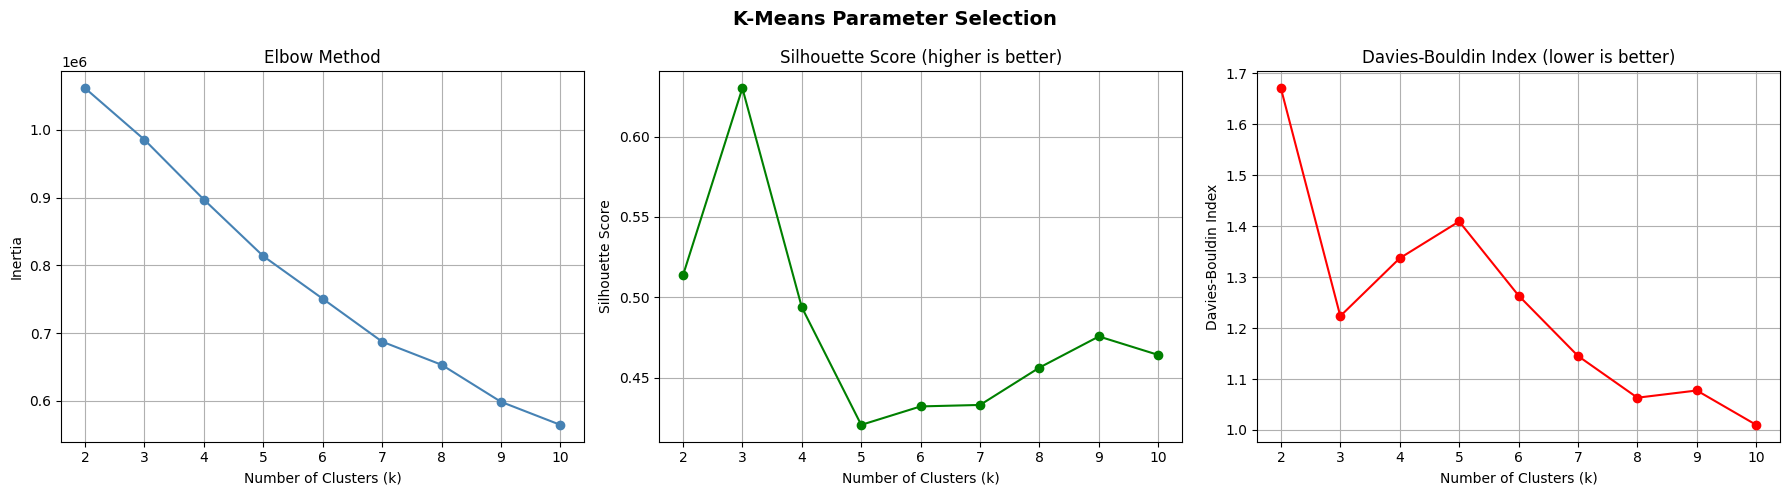


✅ Best k selected: 3
   Silhouette Score : 0.6301
   Davies-Bouldin   : 1.2235

✅ K-Means complete. Cluster labels saved to df.


In [ ]:
# =============================================================
# K-MEANS CLUSTERING
# =============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

k_range = range(2, 11)

inertias          = []
silhouette_scores = []
db_scores         = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)

    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

    print(f"k={k:2d} | Inertia: {km.inertia_:>12.1f} | "
          f"Silhouette: {silhouette_scores[-1]:.4f} | "
          f"Davies-Bouldin: {db_scores[-1]:.4f}")

# -------------------------------------------------------------
# Plots
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(k_range, inertias, marker='o', color='steelblue')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].grid(True)

axes[1].plot(k_range, silhouette_scores, marker='o', color='green')
axes[1].set_title('Silhouette Score (higher is better)')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True)

axes[2].plot(k_range, db_scores, marker='o', color='red')
axes[2].set_title('Davies-Bouldin Index (lower is better)')
axes[2].set_xlabel('Number of Clusters (k)')
axes[2].set_ylabel('Davies-Bouldin Index')
axes[2].grid(True)

plt.suptitle('K-Means Parameter Selection', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# Best k & Final Model
# -------------------------------------------------------------
best_k = silhouette_scores.index(max(silhouette_scores)) + 2

print(f"\nBest k selected: {best_k}")
print(f"   Silhouette Score : {max(silhouette_scores):.4f}")
print(f"   Davies-Bouldin   : {db_scores[best_k - 2]:.4f}")

km_best = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = km_best.fit_predict(X_scaled)

# Save labels back to df (not df_clustering)
df['KMeans_Cluster'] = kmeans_labels
print("\n K-Means complete. Cluster labels saved to df.")